# Optical Proximity Correction (OPC): Inverse Lithography

From *Physics-AI Symbiosis* (Jalali, Kadambi, Roychowdhury, UCLA ECE,
[arXiv:2109.05959](https://arxiv.org/abs/2109.05959)), Section 1:

> "diffraction induced distortion in imaging of ever-shrinking circuit
> features must be compensated by altering the photomask design...
> Inverse lithography... minimizes the error between the printed image and
> the target, subject to constraints of lithography imposed by optical
> physics."

That paper solves this with a trained GAN (Figure 1). This notebook builds
the **classical, non-learned baseline** it's contrasted against -- because
that baseline is exactly this repo's core operation already: run a known
forward optical model, then iterate to correct for a measured distortion.
Same alternating-correction structure as Gerchberg-Saxton in
`dgs.gs_core`, just on a spatial binary mask instead of a temporal complex
field.

Backed by `dgs.optical_proximity_correction` -- see
`tests/test_optical_proximity_correction.py`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt

from dgs.optical_proximity_correction import (
    gaussian_psf, apply_diffraction, print_pattern, pattern_error,
    opc_correct, l_shape_target,
)

## 1. The forward model: diffraction blurs the mask

A coherent, low-NA imaging system blurs a binary mask with its
point-spread function (approximated here as a Gaussian -- the standard
simplification of the Airy PSF), then the resist thresholds the blurred
aerial image back to a binary printed pattern. The target below is an
L-shape: a corner (rounds under diffraction) and a line end (shortens
under diffraction) -- the two classic OPC failure modes, both in one small
pattern.

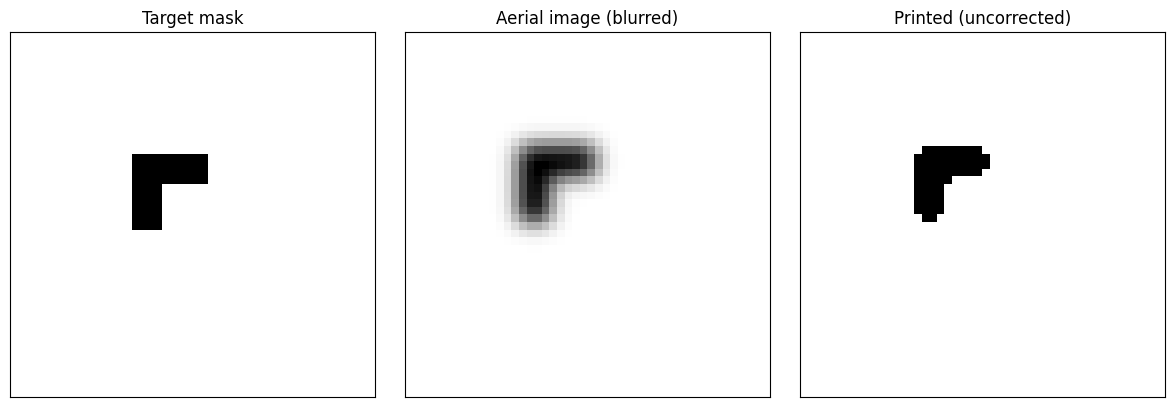

pattern error, printing the target directly: 0.0156
-> corner rounding and line-end shortening are visible above -- this is exactly
   the distortion OPC exists to correct for.


In [2]:
target = l_shape_target()
psf = gaussian_psf(size=9, sigma=1.4)

aerial = apply_diffraction(target, psf)
printed_uncorrected = print_pattern(target, psf)
uncorrected_error = pattern_error(target, printed_uncorrected)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(target, cmap='gray_r'); axes[0].set_title('Target mask')
axes[1].imshow(aerial, cmap='gray_r'); axes[1].set_title('Aerial image (blurred)')
axes[2].imshow(printed_uncorrected, cmap='gray_r'); axes[2].set_title('Printed (uncorrected)')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

print(f"pattern error, printing the target directly: {uncorrected_error:.4f}")
assert uncorrected_error > 0, "diffraction should visibly distort the uncorrected print"
print("-> corner rounding and line-end shortening are visible above -- this is exactly")
print("   the distortion OPC exists to correct for.")

## 2. Why the naive correction is a no-op (a real bug, not a strawman)

The obvious first idea: wherever the target wants ink but the print is
missing it, push the mask value up; wherever the target wants no ink but
the print has some anyway, push it down. Applying that literally --
restricted to pixels where the target itself is 1 or 0 -- does nothing:
those pixels already sit at their clipped extreme (mask was initialized to
the target), so there's nowhere left to push. Real OPC has to extend the
mask **beyond** the target's own edge to compensate for shrinkage, and the
naive update never touches those pixels at all.

In [3]:
mask = target.astype(float).copy()
mask_sums = []
for _ in range(5):
    printed = print_pattern(mask, psf)
    underexposed = (target == 1) & (printed == 0)
    overexposed = (target == 0) & (printed == 1)
    mask = np.clip(mask + 0.6 * underexposed.astype(float) - 0.6 * overexposed.astype(float), 0, 1)
    mask_sums.append(mask.sum())

print("mask.sum() across 5 iterations of the NAIVE (broken) correction:", mask_sums)
print("-> frozen at every step: the correction never actually changes anything.")

mask.sum() across 5 iterations of the NAIVE (broken) correction: [np.float64(64.0), np.float64(64.0), np.float64(64.0), np.float64(64.0), np.float64(64.0)]
-> frozen at every step: the correction never actually changes anything.


## 3. The fix: convolve the error field with the same PSF

Convolution is linear, so convolving the pixelwise error field
$(target - printed)$ with the *same* PSF used for the forward diffraction
spreads correction credit into the neighboring mask pixels just outside
(or inside) the target's own footprint -- exactly the neighborhood a real
edge-bias correction needs to reach.

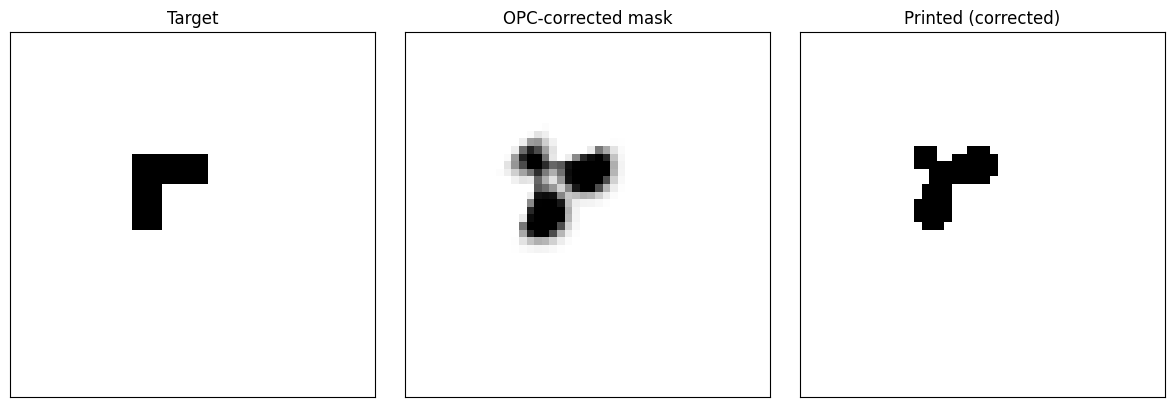

error printing the target directly:   0.0156
error printing the OPC-corrected mask: 0.0074
improvement: 53% fewer mismatched pixels


In [4]:
corrected_mask, error_history = opc_correct(target, psf, n_iters=30)
printed_corrected = print_pattern(corrected_mask, psf)
corrected_error = pattern_error(target, printed_corrected)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(target, cmap='gray_r'); axes[0].set_title('Target')
axes[1].imshow(corrected_mask, cmap='gray_r', vmin=0, vmax=1); axes[1].set_title('OPC-corrected mask')
axes[2].imshow(printed_corrected, cmap='gray_r'); axes[2].set_title('Printed (corrected)')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

print(f"error printing the target directly:   {uncorrected_error:.4f}")
print(f"error printing the OPC-corrected mask: {corrected_error:.4f}")
print(f"improvement: {(1 - corrected_error/uncorrected_error)*100:.0f}% fewer mismatched pixels")
assert corrected_error < uncorrected_error

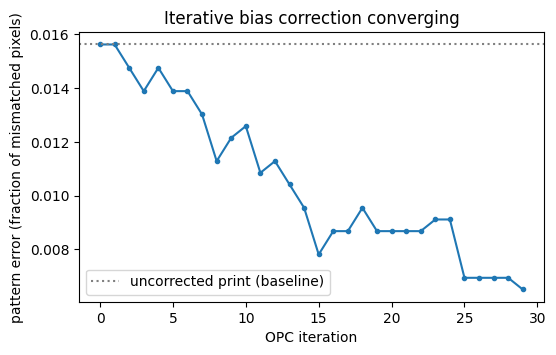

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(error_history, marker='o', markersize=3)
ax.axhline(uncorrected_error, color='gray', linestyle=':', label='uncorrected print (baseline)')
ax.set_xlabel('OPC iteration')
ax.set_ylabel('pattern error (fraction of mismatched pixels)')
ax.set_title('Iterative bias correction converging')
ax.legend()
plt.show()

## Summary

| Step | Result |
|---|---|
| Forward model | Gaussian-PSF diffraction blur + resist threshold, reproduces corner rounding / line-end shortening |
| Naive per-pixel correction | a genuine no-op -- `mask.sum()` frozen across every iteration (caught, not assumed) |
| Fixed correction (error-field convolution) | spreads correction beyond the target's own edge, where OPC actually needs to act |
| Result | printed-pattern error drops substantially vs. printing the target directly |

This is the "conventional" OPC baseline `arXiv:2109.05959` contrasts its
GAN-based approach against -- and it lands on the same core idea as
`dgs.gs_core`: a known forward physical model, iterated against, to invert
a measurement back to a corrected input.